# Discounting : pourquoi 100 € dans un an ne valent pas 100 € aujourd'hui

**Palier :** 0 — Fondations marché
**Niveau :** Accessible
**Durée cible :** 16-18 min
**Prérequis :** P0-6 (no-arbitrage) — recommandé, pas obligatoire.
**Vidéos qui s'appuieront dessus :** FX spot vs forward, Forwards/Futures, Swaps, Pricing d'obligations, toute la famille des taux.

---
> Support de présentation de la vidéo. Entièrement exécuté avant le tournage.

## 1. Question

> Un flux de 100 € dans 5 ans vaut combien aujourd'hui ? Et surtout : pourquoi le marché n'utilise-t-il **pas un seul taux** pour actualiser tous les flux d'une obligation ?

Escompter est l'opération la plus répétée de la finance de marché : chaque prix de forward, de swap, d'obligation ou d'option en dépend. Une erreur ici se propage partout.

## 2. Intuition

Un euro aujourd'hui peut être placé et rapportera un intérêt. Un euro dans un an n'a pas cette possibilité. Donc **le temps a un prix**, et ce prix est celui du taux d'intérêt.

- *Capitaliser* : combien vaudra dans $n$ ans ce que j'ai aujourd'hui ?
- *Actualiser (escompter)* : combien vaut aujourd'hui ce que je recevrai dans $n$ ans ? C'est l'opération inverse.

Deuxième idée, plus importante : un placement à 1 an et un placement à 5 ans n'ont **aucune raison** de rémunérer au même taux. Chaque échéance a son propre taux, le **taux zéro-coupon**. Une obligation est un panier de flux ; chaque flux doit être escompté à *son* taux.

### Glossaire : les mots qu'on va utiliser

| Terme | Définition simple | Exemple |
|---|---|---|
| **Taux d'intérêt** | Le prix du temps : ce qu'on gagne (en %) pour avoir prêté 1 € pendant 1 an. | 4 % → 100 € prêtés rapportent 4 € en un an. |
| **Intérêts composés** | Les intérêts rapportent eux-mêmes des intérêts : on réinvestit ce qu'on a gagné. | 100 € à 10 % : 110 € après 1 an, puis 121 € après 2 ans (pas 120). |
| **Fréquence de composition** ($m$) | Combien de fois par an les intérêts sont ajoutés au capital. | $m=1$ annuel, $m=2$ semestriel, $m=4$ trimestriel. |
| **Composition continue** | Cas limite où les intérêts sont ajoutés à chaque instant ($m \to \infty$). Elle fait apparaître le nombre $e \approx 2{,}718$. | Un taux « continu » se note avec $e^{Rn}$. |
| **Capitaliser** | Aller vers le futur : calculer ce que vaudra un montant d'aujourd'hui. | 100 € placés à 10 % valent 110 € dans 1 an. |
| **Actualiser / escompter** | Aller vers le passé : calculer ce que vaut aujourd'hui un montant futur. | 110 € dans 1 an valent 100 € aujourd'hui à 10 %. |
| **Facteur d'actualisation** (*discount factor*, $DF$) | Le coefficient par lequel on multiplie un flux futur pour avoir sa valeur d'aujourd'hui. Toujours entre 0 et 1 si les taux sont positifs. | $DF=0{,}82$ : 1 € dans 5 ans vaut 0,82 € aujourd'hui. |
| **Flux** (*cash flow*) | Un montant d'argent reçu à une date donnée. | 5 € de coupon dans 2 ans. |
| **Obligation** | Un prêt émis sous forme de titre : l'émetteur verse des coupons réguliers et rembourse le nominal à la fin. | Coupon 5 %, nominal 100, 5 ans : 5, 5, 5, 5, 105. |
| **Nominal** (*face value*) | Le montant remboursé à la fin, sur lequel le coupon est calculé. | 100. |
| **Coupon** | Intérêt versé périodiquement par l'obligation. | 5 % de 100 = 5 € par an. |
| **Maturité** | La date de fin, exprimée ici en années à partir d'aujourd'hui. | 5 ans. |
| **Taux zéro-coupon** ($Z(T)$) | Le taux annuel d'un placement qui ne verse **rien** avant la date $T$ : un seul flux à l'échéance. Il est propre à chaque maturité. | $Z(5)=4\,\%$ : taux d'un placement à 5 ans sans coupon intermédiaire. |
| **Courbe zéro-coupon** | L'ensemble des taux zéro pour toutes les maturités. | 3 % à 1 an, 4 % à 5 ans. |
| **YTM** (*yield to maturity*) | Le **taux unique** qui, appliqué à tous les flux d'une obligation, redonne son prix. Un résumé, pas un taux de marché. | Calculé en 8.1. |
| **Taux forward** | Le taux, déduit de la courbe aujourd'hui, d'un placement qui démarre dans le futur. | « 1 an dans 1 an ». |
| **Interpolation** | Estimer une valeur entre deux points connus. | Z(2,5) entre Z(2) et Z(3). |

## 3. Hypothèses

1. Les flux sont **certains** (pas de risque de défaut) — on escompte au taux sans risque.
2. Une **courbe zéro-coupon unique** sert à escompter tous les flux (cadre simplifié, voir Limites).
3. Les conventions de calendrier sont **ignorées** : une année = 1,0 (pas de Act/360 ici).
4. Les taux utilisés sont **construits pour la pédagogie**, pas des cotations de marché.

## 4. Notation

| Symbole | Signification |
|---|---|
| $R$ | taux annuel (composé $m$ fois par an ou en continu) |
| $m$ | fréquence de composition par an |
| $n$ ou $T$ | durée en années |
| $A$ | montant initial |
| $Z(T)$ | taux zéro-coupon de maturité $T$ (continu) |
| $DF(T)$ | facteur d'actualisation : valeur aujourd'hui de 1 € reçu en $T$ |
| $CF_i$, $t_i$ | flux $i$ d'une obligation et sa date |

## 5. Mathématiques (pas à pas)

On va lire chaque formule **terme par terme**, avec un exemple chiffré à la main, avant de coder.

---
### 5.0 Le point de départ : un exemple sans formule

Je place 100 € à 10 % pendant 1 an. J'obtiens $100 \times 1{,}10 = 110$ €. Ça, c'est le cas simple : intérêts versés **une fois** par an ($m=1$).

Maintenant, la banque dit : « 10 % par an, mais je verse les intérêts **deux fois** par an » ($m=2$). Elle verse donc $10\,\%/2 = 5\,\%$ au bout de 6 mois, puis **encore** 5 % au bout de 12 mois — mais ce second 5 % porte sur 105 €, pas sur 100 € :

$$100 \times 1{,}05 = 105 \qquad 105 \times 1{,}05 = 110{,}25$$

On a donc 110,25 € au lieu de 110. Plus on verse souvent, plus on gagne. C'est tout le mécanisme ; la formule qui suit n'est que cette idée écrite proprement.

---

### 5.1 Capitalisation (Hull 4.1 et 4.2)
$$A\left(1+\frac{R}{m}\right)^{mn} \qquad \text{et, en continu :} \qquad A\,e^{Rn}$$

Lecture terme par terme :
- $A$ : le montant placé au départ (100 €).
- $R$ : le taux **annuel affiché** (10 % = 0,10).
- $m$ : le nombre de versements d'intérêts par an. Chaque versement est de $R/m$ (5 % si $m=2$).
- $n$ : la durée en années. Il y a donc $m\times n$ versements au total, d'où l'exposant $mn$.
- $(1+R/m)$ : le coefficient multiplicateur à chaque versement (1,05).
- **En continu** : quand $m$ devient énorme (versement à chaque seconde), $(1+R/m)^{mn}$ converge vers $e^{Rn}$. Le nombre $e\approx 2{,}718$ n'est pas arbitraire : c'est exactement la limite de cette composition infiniment fréquente. Avantage : $e^{Rn}$ est beaucoup plus simple à manipuler (additionner des durées = multiplier des exponentielles).

### 5.2 Conversion de taux (Hull 4.3 et 4.4)
$$R_c = m\ln\left(1+\frac{R_m}{m}\right) \qquad R_m = m\left(e^{R_c/m}-1\right)$$

**Pourquoi convertir ?** Un taux n'a de sens qu'avec sa fréquence de composition : « 10 % semestriel » et « 10 % continu » ne rapportent pas la même chose. Pour comparer ou combiner deux taux, il faut les mettre dans la même convention.

**D'où vient la formule ?** On cherche le taux continu $R_c$ qui donne **le même résultat** que le taux périodique $R_m$ sur un an : $e^{R_c} = (1+R_m/m)^m$. On prend le logarithme népérien ($\ln$, la fonction inverse de $e^x$) des deux côtés : $R_c = m\ln(1+R_m/m)$. L'autre formule s'obtient en inversant.

- $R_m$ : taux annuel avec $m$ versements par an ; $R_c$ : taux annuel continu.
- Exemple à la main : 10 % semestriel donne $2\ln(1{,}05)=2\times 0{,}04879=0{,}09758$, soit 9,758 % continu. Le taux continu est **plus petit** pour compenser une capitalisation plus fréquente.

### 5.3 Facteur d'actualisation
$$DF(T) = e^{-Z(T)\,T}$$

- $Z(T)$ : le taux zéro continu de la maturité $T$ ; $T$ : la durée en années.
- Pourquoi le signe moins ? Capitaliser multiplie par $e^{+ZT}$ ; actualiser est l'opération inverse, donc on multiplie par $e^{-ZT}=1/e^{ZT}$.
- Exemple : $Z=4\,\%$, $T=5$ : $DF=e^{-0{,}20}=0{,}8187$. Un euro reçu dans 5 ans vaut 0,8187 € aujourd'hui.
- Vérification : $0{,}8187 \times e^{0{,}20} = 1$ : si je place 0,8187 € à 4 % continu pendant 5 ans, je retrouve 1 €.

### 5.4 Valeur d'un flux et prix d'une obligation
$$PV = CF\cdot DF(T) \qquad\qquad P = \sum_i CF_i\; DF(t_i)$$

- $PV$ (*present value*) : valeur actuelle d'**un** flux ; $CF$ : le montant du flux.
- $P$ : prix de l'obligation = somme des valeurs actuelles de **tous** ses flux.
- $\sum_i$ : on additionne pour $i=1$ (premier coupon) jusqu'au dernier flux. Chaque flux $CF_i$ tombe à la date $t_i$ et se multiplie par **son** $DF(t_i)$, donc par le taux zéro **de sa propre date**.
- Pourquoi pas un seul taux ? Une obligation à 5 ans est un panier de 5 placements sans coupon : un à 1 an, un à 2 ans… Chacun a son taux de marché, donc son $DF$.

### 5.5 Lien avec le no-arbitrage

 $DF(T_2)/DF(T_1)$ est le facteur d'actualisation *forward* entre $T_1$ et $T_2$. Si le marché cotait autre chose, on pourrait construire un arbitrage (vidéo précédente).

*Pourquoi ?* Placer 1 € jusqu'en $T_2$ doit rapporter la même chose que placer jusqu'en $T_1$, puis replacer jusqu'en $T_2$ au taux forward. Sinon, deux chemins identiques coûteraient des prix différents.

## 6. Implémentation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 12

### 6.1 Capitaliser : de la composition discrète à la composition continue

**Avant de coder, on refait à la main l'exemple 5.0** (100 € à 10 %, versement semestriel) pour vérifier qu'on a compris la formule.

In [2]:
# À la main : deux versements de 5 %
etape1 = 100 * 1.05
etape2 = etape1 * 1.05
print(etape1, etape2)

# Avec la formule : A * (1 + R/m)**(m*n), A=100, R=0.10, m=2, n=1
print(100 * (1 + 0.10 / 2) ** (2 * 1))

105.0 110.25
110.25


Les deux donnent 110,25 : la formule n'est que la répétition du même geste. On l'emballe maintenant dans une fonction. Le paramètre `m=None` veut dire « pas de fréquence fournie » : dans ce cas on utilise la formule continue (`np.exp`).

In [3]:
def capitalise(A, R, n, m=None):
    """Valeur future. m=None -> composition continue."""
    return A * np.exp(R * n) if m is None else A * (1 + R / m) ** (m * n)

for m in [1, 2, 4, 12, 52, 365]:
    print(f"m = {m:>3} : {capitalise(100, 0.10, 1, m):.2f}")
print(f"continu : {capitalise(100, 0.10, 1):.2f}")

m =   1 : 110.00
m =   2 : 110.25
m =   4 : 110.38
m =  12 : 110.47
m =  52 : 110.51
m = 365 : 110.52
continu : 110.52


**Lecture de la sortie :** plus `m` augmente, plus la valeur monte, mais de moins en moins : 110,00 → 110,25 → 110,38 → … → 110,52. Passer de mensuel à quotidien ne change presque rien : on s'approche de la limite continue (110,52).

### 6.1 bis Conversions de taux

Deux petites fonctions qui traduisent les formules 5.2. `np.log` est le logarithme népérien (ln) ; `np.exp` est $e^x$.

In [4]:
def continu_depuis(Rm, m):   # Hull 4.3
    return m * np.log(1 + Rm / m)

def periodique_depuis(Rc, m):  # Hull 4.4
    return m * (np.exp(Rc / m) - 1)

print(f"10 % semestriel = {continu_depuis(0.10, 2):.3%} continu")
print(f"8 % continu     = {periodique_depuis(0.08, 4):.3%} trimestriel")

10 % semestriel = 9.758% continu
8 % continu     = 8.081% trimestriel


**Lecture :** 10 % versé deux fois par an équivaut à 9,758 % en continu (on retrouve le calcul à la main de 5.2). Et 8 % en continu équivaut à 8,08 % versé quatre fois par an. **Message :** un taux sans sa convention ne veut rien dire.

**Vérification aller-retour** : si on convertit 9,758 % continu en semestriel, on doit retrouver 10 %.

In [5]:
print(f"{periodique_depuis(continu_depuis(0.10, 2), 2):.4%}")

10.0000%


### 6.2 Actualiser : facteur d'actualisation

In [6]:
def discount_factor(Z, T):
    """Valeur aujourd'hui de 1 € reçu en T, taux zéro continu Z."""
    return np.exp(-Z * T)

print(f"DF = {discount_factor(0.04, 5):.4f}")
print(f"100 € dans 5 ans, taux 4 % : {100 * discount_factor(0.04, 5):.2f} € aujourd'hui")
# Vérification : on recapitalise et on doit retrouver 100
print(f"Recapitalisé : {capitalise(100 * discount_factor(0.04, 5), 0.04, 5):.2f}")

DF = 0.8187
100 € dans 5 ans, taux 4 % : 81.87 € aujourd'hui
Recapitalisé : 100.00


**Lecture :** le facteur est 0,8187 ; 100 € futurs valent 81,87 € aujourd'hui. La dernière ligne est un test : on recapitalise ces 81,87 € à 4 % pendant 5 ans et on retombe sur 100. Capitaliser et actualiser sont bien inverses l'un de l'autre.

### 6.3 La courbe zéro-coupon

Jusqu'ici, un seul taux (4 %). Dans la réalité, **chaque maturité a son taux**. On se donne une courbe de 5 points (taux continus, valeurs construites pour la pédagogie).

Le marché ne cote pas toutes les maturités possibles : si j'ai besoin du taux à 2,5 ans, je l'**interpole** (je le déduis des deux points voisins). Ici, interpolation linéaire sur le **taux** : $Z(2{,}5)$ est le milieu entre $Z(2)=3{,}4\,\%$ et $Z(3)=3{,}7\,\%$, soit $3{,}55\,\%$. C'est une simplification (voir Limites).

- `np.interp(T, maturites, zeros)` : renvoie le taux interpolé en `T`.
- `DF(T)` : on combine ensuite ce taux avec la formule 5.3.

In [7]:
maturites = np.array([1, 2, 3, 4, 5])
zeros     = np.array([0.030, 0.034, 0.037, 0.039, 0.040])

def Z(T):
    return np.interp(T, maturites, zeros)

def DF(T):
    return discount_factor(Z(T), T)

for T in maturites:
    print(f"T = {T} an(s) : Z = {Z(T):.2%}   DF = {DF(T):.4f}")

print(f"\nInterpolation : Z(2,5) = {Z(2.5):.2%}   DF(2,5) = {DF(2.5):.4f}")

T = 1 an(s) : Z = 3.00%   DF = 0.9704
T = 2 an(s) : Z = 3.40%   DF = 0.9343
T = 3 an(s) : Z = 3.70%   DF = 0.8949
T = 4 an(s) : Z = 3.90%   DF = 0.8556
T = 5 an(s) : Z = 4.00%   DF = 0.8187

Interpolation : Z(2,5) = 3.55%   DF(2,5) = 0.9151


**Lecture :** les taux montent avec la maturité (3 % à 1 an, 4 % à 5 ans) : prêter plus longtemps est mieux rémunéré. Les facteurs d'actualisation baissent : plus le flux est lointain, moins il vaut aujourd'hui. L'interpolation donne bien 3,55 % à 2,5 ans.

### 6.4 Valoriser une obligation : un flux = un taux

**D'abord à la main, flux par flux.** Obligation de nominal 100, coupon 5 % (donc 5 € par an), maturité 5 ans. Les flux sont 5, 5, 5, 5, puis **105** la dernière année (dernier coupon + remboursement du nominal).

In [8]:
import pandas as pd

annees = np.arange(1, 6)
flux = np.array([5, 5, 5, 5, 105.0])

tableau = pd.DataFrame({
    "année": annees,
    "flux": flux,
    "taux zéro": Z(annees),
    "DF": DF(annees),
})
tableau["valeur actuelle"] = tableau["flux"] * tableau["DF"]
print(tableau.round(4).to_string(index=False))
print(f"\nSomme des valeurs actuelles = prix = {tableau['valeur actuelle'].sum():.2f}")

 année  flux  taux zéro     DF  valeur actuelle
     1   5.0      0.030 0.9704           4.8522
     2   5.0      0.034 0.9343           4.6713
     3   5.0      0.037 0.8949           4.4747
     4   5.0      0.039 0.8556           4.2778
     5 105.0      0.040 0.8187          85.9667

Somme des valeurs actuelles = prix = 104.24


**Comment lire ce tableau :** chaque ligne est un petit placement sans coupon. Le flux de l'année 1 (5 €) est actualisé à 3,0 %, celui de l'année 5 (105 €) à 4,0 %. On multiplie chaque flux par son facteur, on additionne : c'est le prix. Notez que la dernière ligne (105 €) pèse à elle seule environ 86 € sur 104 : c'est le remboursement du nominal qui fait l'essentiel de la valeur.

Maintenant on généralise avec des fonctions : `flux_obligation` fabrique la liste des flux ; `prix_obligation` fait la somme flux × DF (c'est exactement la formule 5.4).

In [9]:
def flux_obligation(coupon, maturite, nominal=100):
    t = np.arange(1, maturite + 1)
    cf = np.full(maturite, float(coupon))
    cf[-1] += nominal
    return t, cf

def prix_obligation(t, cf, df=DF):
    return float(np.sum(cf * df(t)))

t, cf = flux_obligation(coupon=5, maturite=5)
prix = prix_obligation(t, cf)
print(f"Prix de l'obligation 5 ans, coupon 5 % : {prix:.2f}")

Prix de l'obligation 5 ans, coupon 5 % : 104.24


Même résultat que le tableau : 104,24. L'obligation vaut plus que son nominal (100) parce que son coupon (5 %) est supérieur aux taux de marché (3 à 4 %) : elle rapporte plus que ce que le marché exige, donc elle se paie plus cher.

### 6.5 Vérification : on retrouve les exemples de la littérature

Avant de continuer, on vérifie que nos fonctions reproduisent des résultats publiés (Hull, tableaux 4.1 et 4.2 ; CFA). Si on trouve les mêmes chiffres que dans des références reconnues, on peut avoir confiance dans le reste du notebook.

In [10]:
# Hull 4.4 : obligation 2 ans, coupon 6 % semestriel, zéros continus 5,0/5,8/6,4/6,8 %
t_h  = np.array([0.5, 1.0, 1.5, 2.0])
z_h  = np.array([0.050, 0.058, 0.064, 0.068])
cf_h = np.array([3, 3, 3, 103])
print("Hull obligation :", round(float(np.sum(cf_h * np.exp(-z_h * t_h))), 2), "(attendu 98,39)")

# CFA : coupon 4 %, 5 ans, taux plat 6 % annuel
t5 = np.arange(1, 6)
cf4 = np.array([4, 4, 4, 4, 104.0])
print("CFA coupon 4 % :", round(float(np.sum(cf4 / 1.06 ** t5)), 3), "(attendu 91,575)")

Hull obligation : 98.39 (attendu 98,39)
CFA coupon 4 % : 91.575 (attendu 91,575)


## 7. Visualisation

**Graphique 1 — Que se passe-t-il quand on compose de plus en plus souvent ?**

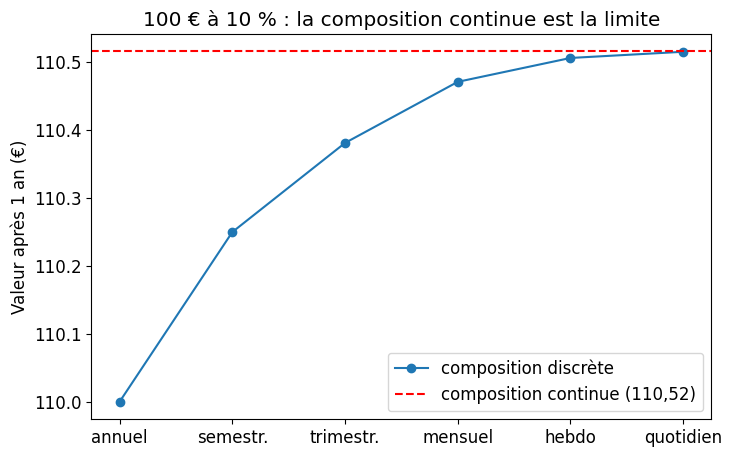

In [11]:
ms = [1, 2, 4, 12, 52, 365]
vals = [capitalise(100, 0.10, 1, m) for m in ms]

fig, ax = plt.subplots()
ax.plot(range(len(ms)), vals, "o-", label="composition discrète")
ax.axhline(capitalise(100, 0.10, 1), color="red", ls="--", label="composition continue (110,52)")
ax.set_xticks(range(len(ms))); ax.set_xticklabels(["annuel", "semestr.", "trimestr.", "mensuel", "hebdo", "quotidien"])
ax.set_ylabel("Valeur après 1 an (€)")
ax.set_title("100 € à 10 % : la composition continue est la limite")
ax.legend(); plt.show()

**Graphique 2 — Combien vaut 1 € reçu dans le futur, selon le taux ?**

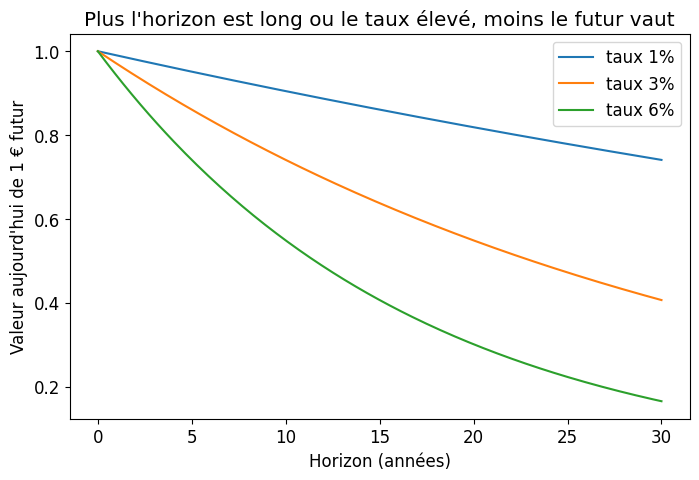

In [12]:
T = np.linspace(0, 30, 200)
fig, ax = plt.subplots()
for r in [0.01, 0.03, 0.06]:
    ax.plot(T, np.exp(-r * T), label=f"taux {r:.0%}")
ax.set_xlabel("Horizon (années)"); ax.set_ylabel("Valeur aujourd'hui de 1 € futur")
ax.set_title("Plus l'horizon est long ou le taux élevé, moins le futur vaut")
ax.legend(); plt.show()

**Graphique 3 — La courbe zéro-coupon et les facteurs d'actualisation qu'elle implique**

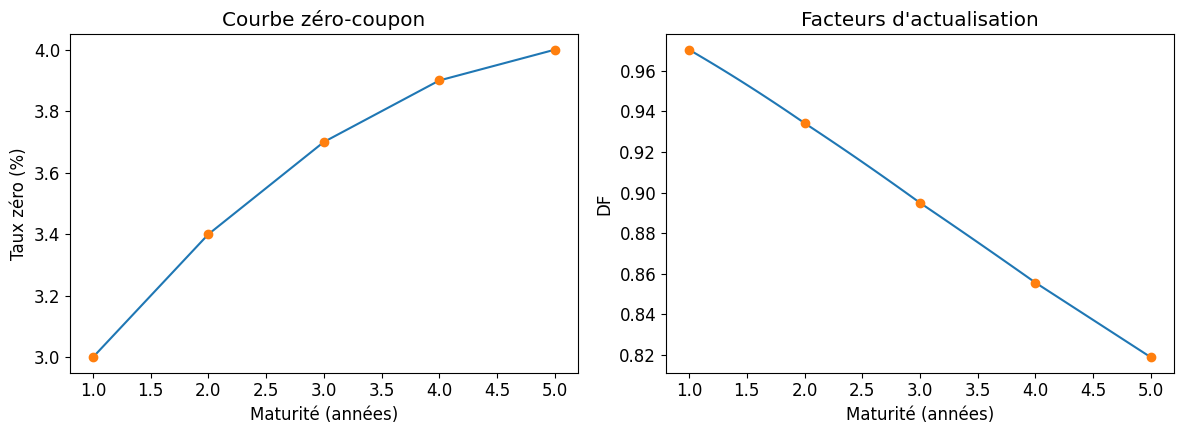

In [13]:
Tg = np.linspace(1, 5, 100)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
a1.plot(Tg, Z(Tg) * 100); a1.plot(maturites, zeros * 100, "o")
a1.set_xlabel("Maturité (années)"); a1.set_ylabel("Taux zéro (%)"); a1.set_title("Courbe zéro-coupon")
a2.plot(Tg, DF(Tg)); a2.plot(maturites, DF(maturites), "o")
a2.set_xlabel("Maturité (années)"); a2.set_ylabel("DF"); a2.set_title("Facteurs d'actualisation")
plt.tight_layout(); plt.show()

## 8. Expériences

### 8.1 Un seul taux ou la courbe ? Le piège du « yield to maturity »

On prend trois obligations de même maturité (5 ans), de coupons différents (1 %, 5 %, 8 %), toutes valorisées avec la **même courbe**. On calcule ensuite, pour chaque prix, le taux unique qui, appliqué à tous les flux, redonne ce prix (le *yield to maturity*).

**Ce qu'on fait exactement :**
1. Pour chaque obligation, on calcule le prix **avec la courbe** (une valeur par flux).
2. On cherche ensuite le taux unique $y$ tel que $\sum_i CF_i/(1+y)^{t_i} = \text{prix}$. Il n'y a pas de formule fermée : on le trouve par recherche numérique. `brentq(f, a, b)` trouve la valeur de $y$ entre $a$ et $b$ qui annule la fonction `f` (ici : écart entre prix recalculé et prix cible).
3. Convention : le YTM est ici en composition **annuelle**, alors que la courbe est en continu (4,00 % continu ≈ 4,08 % annuel). On compare donc des ordres de grandeur, pas des égalités.

In [14]:
def ytm(t, cf, prix):
    return brentq(lambda y: np.sum(cf / (1 + y) ** t) - prix, -0.5, 1.0)

print(f"{'coupon':>7} {'prix':>9} {'YTM':>8}")
for c in [1, 5, 8]:
    t, cf = flux_obligation(c, 5)
    p = prix_obligation(t, cf)
    print(f"{c:>6}% {p:9.2f} {ytm(t, cf, p):8.3%}")

 coupon      prix      YTM
     1%     86.35   4.073%
     5%    104.24   4.046%
     8%    117.66   4.029%


**Lecture :** trois obligations, une seule courbe, mais trois YTM différents (4,07 % / 4,05 % / 4,03 %). Le YTM est, en gros, une *moyenne* des taux zéro pondérée par les flux — pas un taux de marché. La courbe zéro, elle, est unique : c'est elle qui est la référence.

**Pourquoi c'est important ?** Un coupon élevé verse plus d'argent tôt (taux bas), un coupon faible concentre les flux à la fin (taux élevé). Le « taux moyen » qui résume chaque obligation est donc différent, alors que le marché n'a coté qu'une seule courbe. Comparer deux obligations par leur YTM est utile, mais ne remplace jamais la courbe.

### 8.2 Choc de +1 % sur toute la courbe

Quel effet sur le prix de l'obligation 5 ans à coupon 5 % ?

**Ce qu'on fait :** on ajoute 0,01 (1 point de pourcentage) à chaque taux zéro, on recalcule chaque $DF$ avec ces nouveaux taux (`lambda` = petite fonction écrite sur une ligne), puis on refait la somme flux × DF. Le prix baisse : des taux plus élevés rendent les flux futurs moins précieux. Plus la maturité est longue, plus l'effet est fort.

In [15]:
t, cf = flux_obligation(5, 5)
p0 = prix_obligation(t, cf)
df_choc = lambda tt: np.exp(-(Z(tt) + 0.01) * tt)
p1 = prix_obligation(t, cf, df_choc)
print(f"Prix initial : {p0:.2f}   après +1 % : {p1:.2f}   variation : {p1 / p0 - 1:.2%}")

Prix initial : 104.24   après +1 % : 99.61   variation : -4.44%


### 8.3 Le facteur d'actualisation forward

$DF(2)/DF(1)$ est la valeur aujourd'hui de 1 € reçu dans 2 ans, **exprimée en euros de l'année 1**. En termes de taux : le taux forward 1 an dans 1 an.

**Raisonnement :** placer 1 € sur 2 ans au taux zéro 2 ans (3,4 %) doit rapporter autant que placer 1 an à 3,0 % puis replacer 1 an au taux forward $f$. Donc $2\times 3{,}4\,\% = 1\times 3{,}0\,\% + f$, d'où $f = 6{,}8-3{,}0 = 3{,}8\,\%$. C'est ce que calcule `np.log(DF(1)/DF(2))` : le $\ln$ du rapport des facteurs. Si le marché cotait autre chose, il y aurait un arbitrage (vidéo précédente).

In [16]:
df_fwd = DF(2) / DF(1)
taux_fwd = np.log(DF(1) / DF(2))   # sur 1 an, continu
print(f"DF forward (1 an -> 2 ans) : {df_fwd:.4f}")
print(f"Taux forward 1 an dans 1 an : {taux_fwd:.2%}  (= 2*3,4 % - 1*3,0 % = 3,8 %)")

DF forward (1 an -> 2 ans) : 0.9627
Taux forward 1 an dans 1 an : 3.80%  (= 2*3,4 % - 1*3,0 % = 3,8 %)


## 9. Résultats

- 100 € dans 5 ans valent **81,87 €** aujourd'hui (taux zéro 5 ans = 4,0 % continu).
- L'obligation 5 ans à coupon 5 % vaut **104,24 €** avec la courbe.
- Trois coupons différents donnent trois YTM différents sur la **même** courbe.
- Un choc parallèle de +1 % fait perdre environ **4,4 %** de valeur à cette obligation.
- La courbe d'escompte *contient* les taux forward : 3,8 % pour 1 an dans 1 an.

## 10. Interprétation financière

- **Trader / desk taux :** il ne cote pas « un taux », il travaille avec une courbe. Le choc de +1 % de 8.2 est le raisonnement derrière la **DV01** (prochaines vidéos).
- **Structureur :** le prix d'un produit structuré est la somme de flux escomptés ; toute erreur de courbe se répercute sur chaque ligne.
- **Quant / risk manager :** la courbe d'escompte est la brique d'entrée de presque tous les modèles de pricing.
- **Lien no-arbitrage :** le forward implicite de 8.3 n'est pas une prévision, c'est une conséquence — comme le forward FX de la vidéo précédente.

## 11. Limites

- **Un seul taux sans risque** : on a ignoré le risque de crédit (un émetteur risqué s'escompte avec un spread) et le fait que, depuis la crise de 2008, les marchés utilisent des courbes distinctes pour escompter et pour projeter (multi-curve, OIS). Hors périmètre ici.
- **Conventions de calendrier ignorées** : le marché utilise Act/360, Act/365, 30/360 selon les produits ; on y reviendra avec les forwards FX.
- **Interpolation simpliste** : l'interpolation linéaire du taux est un choix parmi d'autres, avec des conséquences sur les forwards implicites.
- **Courbe donnée, pas construite** : on a pris les taux zéro comme donnés. En pratique on les extrait de prix de marché (bootstrapping) — sujet d'une vidéo dédiée.
- **Taux construits pour la pédagogie**, pas des cotations réelles.

## 12. Conclusion

> **Un euro n'a pas de valeur sans date. Pour le valoriser, on l'escompte au taux de *son* échéance : c'est la courbe zéro-coupon, pas un taux unique, qui fait le prix.**

## À vous de jouer

- Modifiez `zeros` pour obtenir une courbe **inversée** (taux court > taux long). Que devient le taux forward 1 an dans 1 an ?
- Changez la maturité à 10 ans en étendant la courbe : l'écart entre les YTM des obligations à coupons différents augmente-t-il ?
- Vérifiez que `prix_obligation` d'une obligation à coupon nul sur 5 ans retrouve bien `100 * DF(5)`.

Code source complet et notebooks des autres vidéos : [github.com/dmorabi](https://github.com/dmorabi)
Repo de cette vidéo : `04-discounting/notebook.ipynb`

---
## Sources

- J. Hull, *Options, Futures and Other Derivatives*, 8e éd., chapitre 4 : équations (4.1)-(4.4), tableaux 4.1 et 4.2, exemples 4.1 et 4.2.
- CFA Institute, *Fixed Income Analysis* (Petitt, 2022) : facteur d'actualisation, obligation comme portefeuille de zéro-coupons, exemple d'évaluation à taux plat.
- Support de cours interne (`Rates_merged_watermark.pdf`).

*Les taux utilisés sont construits pour la pédagogie.*